# Lesson 04 — Derivatives as direction

Goal: compute the **slope of the loss** at any spot by "sliding your foot" a tiny bit, then use it to know which way to turn a knob.

- slope = rise ÷ run = (loss after a tiny slide − loss here) ÷ tiny slide
- slope **negative** → increase the knob · **positive** → decrease it · **≈ 0** → at the bottom

Run each cell with **Shift+Enter**. Fill in every `TODO`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def predict(x, m, b):
    return m * x + b

def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

## Step 1 — The tiny loss

One pizza: size 1, real price 3. The loss is `(3 - m) ** 2`.

**TODO:** Write `tiny_loss(m)`. Check: `tiny_loss(1)` → 4, `tiny_loss(3)` → 0.

In [6]:
def tiny_loss(m):
    # TODO
    return (3 - m) ** 2

print(tiny_loss(1))
print(tiny_loss(3))

4
0


## Step 2 — Slide your foot: the slope function

**TODO:** Write `slope(f, m, h)`. It takes:
- `f`: any loss function of one knob (e.g. `tiny_loss`)
- `m`: where you're standing
- `h`: how far to slide your foot (a tiny number)

and returns rise ÷ run.

Then check against the hand-worked table, using `h = 0.1`: m = 1 → −3.9, m = 5 → +4.1, m = 3 → ≈ 0.1.

*Hint:* in Python you can pass a function as an argument, then call it inside: `f(m)`.

In [7]:
def slope(f, m, h=0.001):
    # TODO
    loss_m = f(m)
    loss_mh = f(m + h)
    rise = loss_mh - loss_m
    return rise/h

# TODO: check m = 1, 5, 3 with h = 0.1
print(slope(tiny_loss, 1, 0.1))
print(slope(tiny_loss, 5, 0.1))
print(slope(tiny_loss, 3, 0.1))

-3.9000000000000012
4.099999999999984
0.10000000000000017


## Step 3 — Why "tiny"?

**TODO:** At `m = 1`, print the slope for `h` = 0.1, 0.01, 0.001, 0.0001.

**Question:** What number is it getting closer to?

In [ ]:
# TODO
print(slope(tiny_loss, 1, 0.1))
print(slope(tiny_loss, 1, 0.01))
print(slope(tiny_loss, 1, 0.001))
print(slope(tiny_loss, 1, 0.0001))

# It gets closer to: -4.0 

-3.9000000000000012
-3.9899999999999824
-3.9989999999994197
-3.999900000000167


## Step 4 — See the slope: draw tangent lines

A **tangent line** touches the curve at one spot and has the same tilt as the curve there. It's a straight line, so it's Lesson 02's `y = m × x + b` again!

**TODO:**
1. Plot `tiny_loss` for m from 0 to 6.
2. At m = 1, 3 and 5, draw a short tangent line.

*Hint:* the tangent at spot `m0` is the line
`loss_here + s * (m - m0)`, where `s = slope(tiny_loss, m0)` and `loss_here = tiny_loss(m0)`.
Draw it only for m within ±0.8 of `m0`, so it stays short.

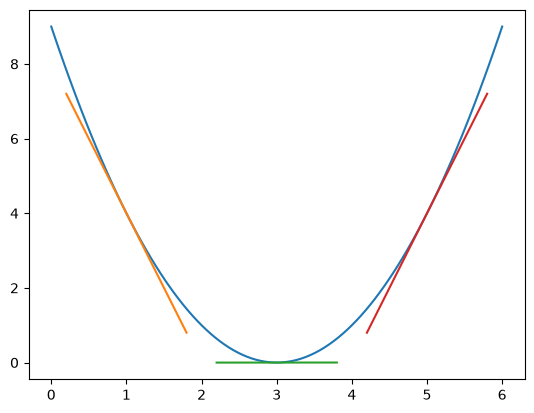

In [72]:
# TODO
ms = np.linspace(0, 6, 100)
plt.plot(ms, tiny_loss(ms))                       # smooth bowl

for spot in [1, 3, 5]:
    height = tiny_loss(spot)                      # measured ONCE, at the spot
    s = slope(tiny_loss, spot)                    # measured ONCE, at the spot
    xs = np.linspace(spot - 0.8, spot + 0.8, 2)   # left end, right end
    plt.plot(xs, height + s * (xs - spot))        # the ruler: a straight line

plt.show()

## Step 5 — The real pizza loss ⭐

Back to the 5 pizzas from Lesson 03, with `b = 1.089` fixed. In Lesson 03 you found the bottom of this loss curve at m ≈ 1.03.

**TODO:**
1. Write `pizza_loss(m)`: the MSE of the pizza line for that `m` (b fixed).
2. Compute its slope at m = 0.7, 1.03, 1.3.
3. For each, write which way you'd turn `m`.

**Question:** Do the signs agree with the Lesson 03 loss curve?

In [65]:
sizes  = np.array([6, 8, 10, 12, 14])
prices = np.array([7.0, 9.5, 11.0, 13.8, 15.6])
b = 1.089

# TODO
def pizza_loss(m):
    return sum((m * sizes + b - prices) ** 2) / 5

print("m = 0.7 ->", slope(pizza_loss, 0.7, 0.0001))
print("m = 1.03 ->", slope(pizza_loss, 1.03, 0.0001))
print("m = 1.3 ->", slope(pizza_loss, 1.3, 0.0001))

# m = 0.7  -> slope -71.80920000001478 -> turn m up
# m = 1.03 -> slope -0.5292000000015062 -> turn m up
# m = 1.3  -> slope 57.79080000000825 -> turn m down

# Yes the signs agree with Lession 3.

m = 0.7 -> -71.80920000001478
m = 1.03 -> -0.5292000000015062
m = 1.3 -> 57.79080000000825


## Bonus — Every knob gets its own slope

The line has **two** knobs. Each one has its own slope: "how does the loss change if I nudge *only this* knob?"

**TODO:** Fix `m = 1.03`. Write `pizza_loss_b(b)` and compute its slope at `b = 1.089`. Should you increase or decrease `b`?

*(Lesson 03's solution found a better line at m = 1.075, b = 0.63. Does your answer point that way?)*

In [61]:
# TODO
m = 1.03
def pizza_loss_b(b):
    return sum((m * sizes + b - prices) ** 2) / 5

print(slope(pizza_loss_b, 1.089, 0.01))

# I would decrease b

0.028000000000000247
